# 6. Validación estadística del modelo original

**Pregunta (condición R3):** ¿el HGSB tiene un error menor que el de los benchmarks, con una diferencia
estadísticamente significativa y no trivial?

## 6.1 Protocolo común

- **Mismas particiones y semilla** que los 28 benchmarks: hold-out por activo (139 activos), 10 pliegues
  externos y 3 internos GroupKFold, semilla 42. El HGSB pasó por la misma búsqueda bayesiana con el mismo
  presupuesto de 30 evaluaciones (pareado estricto).
- **Comparador principal:** la mejor combinación benchmark por RMSE medio del bucle externo. La definición de
  superioridad (guía 6.1) exige además superar la mejor combinación de **cada** uno de los 7 modelos.
- **Tipo de datos:** panel activo-año, de corte transversal entre activos. Por eso las pruebas principales son las
  de la columna de corte transversal de la guía (Tabla 3): Wilcoxon por pliegue, t corregida de Nadeau-Bengio,
  permutación pareada y bootstrap pareado BCa. Las dos últimas se hacen a nivel de **activo** (139 unidades
  independientes), porque las filas de un mismo activo están correlacionadas (ρ = 0.75 en los residuos).
- **Procedimiento global:** Model Confidence Set {cite}`hansen2011model` con el HGSB dentro del universo de 29
  modelos, con bootstrap estacionario sobre las filas ordenadas por activo y año. Así los bloques respetan la
  dependencia dentro del activo. Se complementa con Friedman + Nemenyi {cite}`demsar2006statistical` sobre los
  10 pliegues.
- **Comparaciones múltiples:** Holm sobre las cuatro pruebas dirigidas; se reportan el p crudo y el ajustado.
- **Tamaño del efecto:** δ de Cliff (umbral de no despreciable |δ| ≥ 0.147 {cite}`romano2006appropriate`) y d de
  Cohen pareado.

In [1]:
import sys, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src import config as C
from src.stats_tests import cd_diagram
from src.viz import set_style, SERIES

set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
ORIG = C.RESULTS_DIR / "original"
F = pd.read_csv(ORIG / "folds.csv", index_col=0)
fr = json.load(open(ORIG / "friedman.json"))
verdict = json.load(open(ORIG / "verdict.json", encoding="utf-8"))
best = fr["best_benchmark"]

## 6.2 Tabla resumen

In [2]:
lb = pd.read_csv(C.ROOT / "artifacts" / "leaderboard.csv")
summary = pd.DataFrame({
    "Modelo": lb.label, "Optimizador": lb.method,
    "RMSE externo": [f"{a:.3f} ± {b:.3f}" for a, b in zip(lb.outer_rmse_mean, lb.outer_rmse_std)],
    "RMSE prueba": lb.test_rmse, "R² prueba": lb.test_r2,
    "Cobertura IC 90 %": lb.coverage_test, "Inferencia (ms/fila)": lb.infer_ms_per_row,
}).sort_values("RMSE prueba")
master = pd.read_csv(C.RESULTS_DIR / "master_table.csv")
times = master[master.scenario == "A_estructural"].set_index(["model", "method"])["fit_time_s"]
summary

,Modelo,Optimizador,RMSE externo,RMSE prueba,R² prueba,Cobertura IC 90 %,Inferencia (ms/fila)
5,XGBoost,Grid,2.057 ± 0.600,1.6481,0.9196,0.9359,0.0498
4,Random Forest,Random,2.008 ± 0.549,1.7171,0.9127,0.9319,0.0483
7,HGSB · modelo original,Bayesiana,1.927 ± 0.579,1.8837,0.8949,0.9105,0.0886
3,Árbol de decisión,Genetica,2.448 ± 0.886,1.9326,0.8894,0.9426,0.0109
0,KNN,Bayesiana,2.613 ± 0.659,2.1281,0.8659,0.9292,0.1833
6,SVR (RBF),Bayesiana,2.187 ± 0.529,2.1597,0.8619,0.9266,0.6049
2,Lasso,Bayesiana,2.705 ± 0.575,2.6402,0.7936,0.9266,0.0099
1,Ridge,Random,2.683 ± 0.553,2.6703,0.7888,0.9226,0.0098


## 6.3 Supuestos

- **Wilcoxon:** supone diferencias pareadas simétricas alrededor de la mediana; se revisa con la asimetría de
  $\Delta$RMSE.
- **t de Nadeau-Bengio** {cite}`nadeau2003inference`: supone normalidad aproximada de $\Delta$RMSE (Shapiro-Wilk)
  y corrige la varianza por el solapamiento de los conjuntos de entrenamiento:
  $\hat\sigma^2_{\mathrm{corr}} = \big(\tfrac1k + \tfrac{n_{\mathrm{test}}}{n_{\mathrm{train}}}\big)\hat\sigma^2$.
- **Permutación y bootstrap por activo:** suponen activos intercambiables e independientes entre sí; la dependencia
  dentro del activo se respeta al tomarlo como unidad.
- **MCS:** supone estacionariedad de las diferencias de pérdida; el bootstrap estacionario por bloques
  {cite}`politis1994stationary` respeta la dependencia en el orden activo-año.

In [3]:
d = F["HGSB|Bayesiana"] - F[best]
print(f"ΔRMSE por pliegue (HGSB − {best}):", np.round(d.values, 3))
print(f"media {d.mean():+.4f} · mediana {d.median():+.4f} · asimetría {stats.skew(d):.2f}")
print(f"Shapiro-Wilk p = {stats.shapiro(d).pvalue:.3f}  (H0: normalidad)")
print(f"Pliegues en que el HGSB es mejor: {(d < 0).sum()}/10")

ΔRMSE por pliegue (HGSB − RandomForest|Random): [-0.256 -0.066 -0.272 -0.076 -0.023 -0.091  0.072  0.13   0.234 -0.458]
media -0.0807 · mediana -0.0713 · asimetría -0.29
Shapiro-Wilk p = 0.922  (H0: normalidad)
Pliegues en que el HGSB es mejor: 7/10


## 6.4 Pruebas de hipótesis

In [4]:
tests = pd.read_csv(ORIG / "tests.csv")
tests

,Prueba,H0,Supuestos,Estadístico,p crudo,p ajustado (Holm),Tamaño del efecto,Conclusión
0,Wilcoxon (pliegues),Mediana de ΔRMSE por pliegue = 0,Pares por pliegue; diferencias simétricas,W = 16.0,0.1377,0.5508,δ de Cliff = -0.140 (despreciable),No rechaza H0
1,t corregida de Nadeau-Bengio,E[ΔRMSE] = 0,Normalidad aprox. de ΔRMSE; corrección por sol...,t = -0.855,0.2074,0.6221,d de Cohen = -0.393 (pequeño),No rechaza H0
2,Permutación pareada por activo (prueba),E[L_HGSB − L_bench] = 0 por activo,Activos independientes; intercambiabilidad del...,Δ pérdida = 0.603,0.5745,1.0000,d de Cohen (activos) = 0.055 (despreciable),No rechaza H0
3,Bootstrap BCa por activo (prueba),RMSE_HGSB − RMSE_bench = 0,Remuestreo de activos (conglomerados),"ΔRMSE = 0.167 [-0.088, 0.809]",0.7818,1.0000,ΔRMSE = +0.167 USD/Bbl,No rechaza H0
4,"MCS (global, α = 0.10)",El benchmark pertenece al conjunto de los mejores,Bootstrap estacionario (orden activo-año),p_MCS bench = 0.672; p_MCS HGSB = 0.609,0.6725,—,—,No rechaza H0


## 6.5 Procedimiento global: Friedman, Nemenyi y MCS

Friedman (7 mejores combinaciones + HGSB): χ² = 45.27, p = 1.21e-07, W de Kendall = 0.647; CD de Nemenyi = 3.32


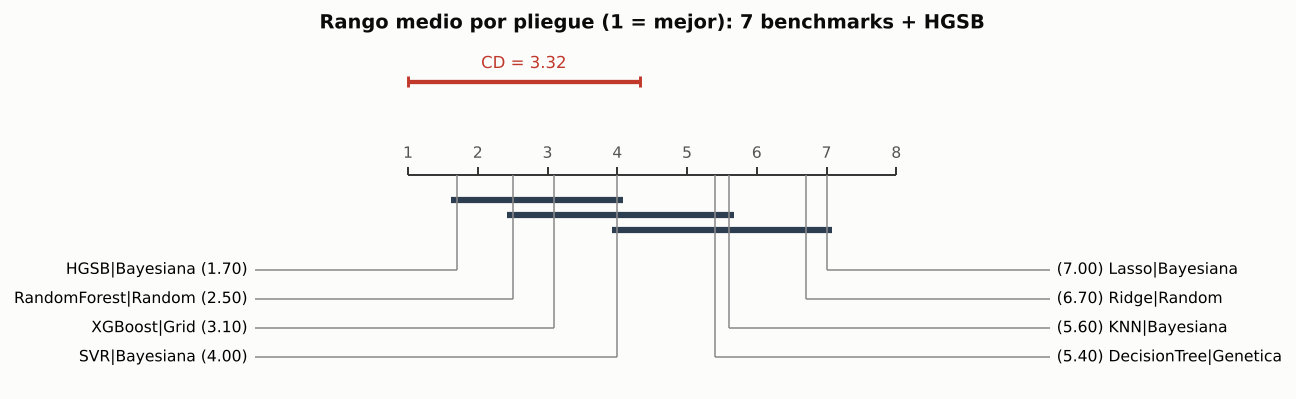

In [5]:
f8 = fr["friedman_8"]
print(f"Friedman (7 mejores combinaciones + HGSB): χ² = {f8['chi2']:.2f}, p = {f8['p_value']:.2e}, "
      f"W de Kendall = {f8['kendall_W']:.3f}; CD de Nemenyi = {fr['cd_8']:.2f}")
ranks = pd.Series(fr["ranks_8"]).sort_values()
fig, ax = plt.subplots(figsize=(9, 3.2))
cd_diagram(ranks, fr["cd_8"], ax=ax, title="Rango medio por pliegue (1 = mejor): 7 benchmarks + HGSB")
plt.show()

In [6]:
mcs = pd.read_csv(ORIG / "mcs.csv")
mcs[["model", "RMSE", "p_mcs", "in_mcs", "elim_order"]].head(15)

,model,RMSE,p_mcs,in_mcs,elim_order
0,XGBoost|Random,1.5958,1.0000,True,29
1,XGBoost|Bayesiana,1.6235,0.7755,True,28
2,XGBoost|Grid,1.6481,0.7755,True,27
3,RandomForest|Bayesiana,1.6544,0.7755,True,26
4,RandomForest|Genetica,1.6993,0.6725,True,25
5,XGBoost|Genetica,1.7097,0.6725,True,24
6,RandomForest|Random,1.7171,0.6725,True,23
7,RandomForest|Grid,1.7212,0.6085,True,22
8,HGSB|Bayesiana,1.8837,0.6085,True,21
9,DecisionTree|Random,1.9208,0.5235,True,20


## 6.6 Intervalos de confianza y robustez

Semillas: 1.856 ± 0.020


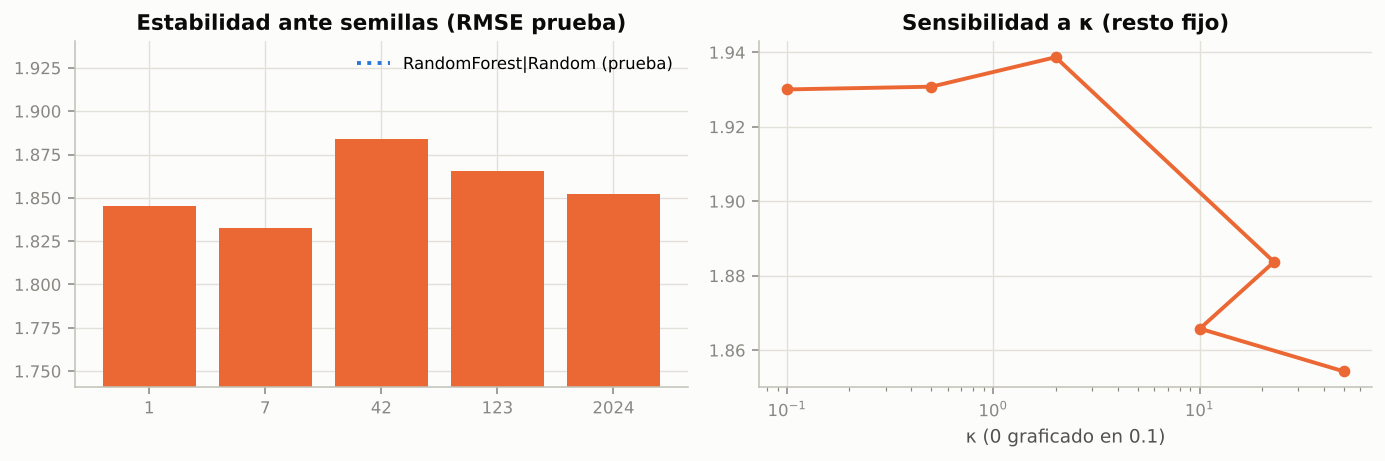

,kappa,test_rmse
0,0.0000,1.9300
1,0.5000,1.9308
2,2.0000,1.9387
3,22.8713,1.8837
4,10.0000,1.8658
5,50.0000,1.8543


In [7]:
seeds = pd.read_csv(ORIG / "seeds.csv")
kap = pd.read_csv(ORIG / "kappa.csv")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].bar(seeds.seed.astype(str), seeds.test_rmse, color=SERIES[1])
axes[0].axhline(verdict["bench_test_rmse"], ls=":", color=SERIES[0], label=f"{best} (prueba)")
axes[0].set_ylim(seeds.test_rmse.min() * 0.95, max(seeds.test_rmse.max(), verdict["bench_test_rmse"]) * 1.03)
axes[0].set_title("Estabilidad ante semillas (RMSE prueba)"); axes[0].legend()
axes[1].semilogx(kap.kappa.replace(0, 0.1), kap.test_rmse, "o-", color=SERIES[1])
axes[1].set_xlabel("κ (0 graficado en 0.1)"); axes[1].set_title("Sensibilidad a κ (resto fijo)")
fig.tight_layout(); plt.show()
print(f"Semillas: {seeds.test_rmse.mean():.3f} ± {seeds.test_rmse.std(ddof=1):.3f}")
kap

La sensibilidad a κ es **descriptiva** (se mide en el hold-out con los demás hiperparámetros fijos): no se usó
para elegir κ, que salió de la búsqueda anidada.

## 6.7 Veredicto

In [8]:
print(verdict["text"])

HGSB: RMSE externo 1.927 ± 0.579 frente a 2.008 ± 0.549 del mejor benchmark (RandomForest|Random); en prueba 1.884 vs 1.717. 0 de 5 pruebas rechazan H0 (Holm / MCS); δ de Cliff = -0.140. No cumple R3: la diferencia no es estadísticamente significativa con las correcciones exigidas.


### Discusión

La superioridad se juzga con las tres condiciones de la guía (6.1): (1) menor RMSE medio externo que la mejor
combinación benchmark y que la mejor de cada modelo; (2) al menos tres pruebas que rechacen H0 con p ajustado
< 0.05 (< 0.10 para el MCS); y (3) |δ de Cliff| ≥ 0.147. Si alguna falla, el resultado se reporta como **no
superior**. Las causas probables se discuten con la evidencia de este capítulo: poca potencia con 10 pliegues,
un efecto propio del activo que ningún modelo observa (correlación de errores ≥ 0.57 entre todos los modelos) y
la alta variación entre pliegues (d.e. ≈ 0.55 USD/Bbl, del mismo orden que las diferencias entre modelos).